# 01. The site and the LiDAR rasters

This notebook covers **phase 1** of the project: from a site drawn in QGIS and a classified airborne LiDAR
point cloud to the rasters that every later step uses (terrain, buildings, vegetation), and the candidate
sensor positions.

It runs on the site of `data/site`, drawn in QGIS on the MRNF LiDAR tiles. The outputs it reads are produced
by the computation chain of the main README.

| Step | Module | Output |
|---|---|---|
| Assets, weighted surfaces, grid | `src.site` | `site_derived.gpkg`, `weights.csv`, `grid.yaml` |
| Rasters by block accumulation | `src.rasters` | `dtm.tif`, `dsm.tif`, `building_h.tif`, `other_h.tif`, `gap_fraction.tif`, ... |
| Candidate positions | `src.candidates` | `candidates.gpkg` |

In [13]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src.analysis, src.intruder_evaluation, src.nsga_analysis, src.pareto  # noqa: F401  (they select the Agg backend)
from src.site import load_config

%matplotlib inline

cfg = load_config()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
pd.set_option("display.width", 160)

## 1. The site drawn in QGIS

A site is a GeoPackage with three layers (see `docs/qgis_site_guide.md`):

| Layer | Geometry | Meaning |
|---|---|---|
| `perimeter` | polygon | the fence |
| `zones` | polygons | a partition of the perimeter, each with a `level`, a `weight` and one `intruder_target` |
| `access` | points | the gates, snapped on the fence, with their width in the `type` field |

Every layer is in the LiDAR projection (EPSG:2950, NAD83(CSRS) / MTM zone 8), and each zone has a `type`
(`Building`, `Equipment` or `Periphery`):

In [14]:
from src.site import read_layer

raw = {name: read_layer(Path(cfg["site"]["gpkg"]), name) for name in ("perimeter", "zones", "access")}
for name, g in raw.items():
    print(f"{name}: {len(g)} feature(s), CRS EPSG:{g.crs.to_epsg()}")
    display(g.drop(columns="geometry"))

perimeter: 1 feature(s), CRS EPSG:2950


,name,fence_type
0,Site Beta,Wire mesh fence 2m


zones: 5 feature(s), CRS EPSG:2950


,name,level,weight,intruder_target,type
0,Building 2,3,2.0,False,Building
1,Building 3,3,2.0,False,Building
2,Core,10,15.0,True,Building
3,Grounds,1,1.0,False,Periphery
4,Building 1,3,3.0,False,Building


access: 3 feature(s), CRS EPSG:2950


,name,type
0,Car gate,Sliding gate 5m
1,Pedestrian entrance,Gate 1.5m
2,Vehicle gate,Sliding gate 4m


## 2. Assets and weighted surfaces

`src.site` then validates the drawing (the zones must partition the perimeter within 0.5 m², the gates must
lie on the fence, exactly one target...) and separates two things:

- **assets** (buildings, equipment): the targets of the intruder and opaque obstacles;
- **surfaces to watch**: a 15 m **approach ring** around each asset, which carries the weight of the asset,
  plus the rest of the ground (periphery). Where rings overlap, a surface takes the weight of the most
  important asset it serves.

A cell $i$ of 1 m² in a surface of weight $w_z$ gets the weight $w_i = w_z$. The optimiser will maximise a
weighted coverage, so the share of a surface in the objective is

$$
\text{share}_z = \frac{w_z A_z}{\sum_{z'} w_{z'} A_{z'}},
$$

where $A_z$ is its ground area. A large surface with a small weight can outweigh a small critical one:
this table is worth checking before any optimisation.

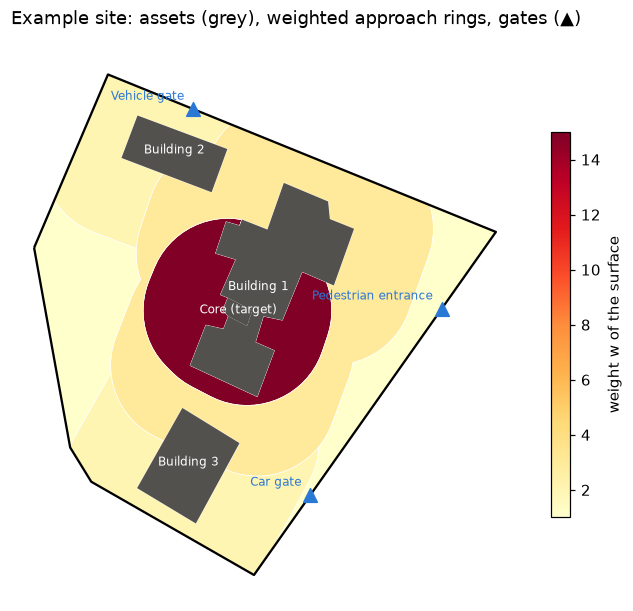

,source,role,level,weight,area_m2,weight_x_area,objective_share_pct
0,Core,approach,10,15.0,580.6,8709.0,54.6
1,Building 1,approach,3,3.0,1487.4,4462.3,28.0
2,Building 3,approach,3,2.0,529.7,1059.4,6.6
3,Building 2,approach,3,2.0,435.1,870.3,5.5
4,periphery,periphery,1,1.0,850.7,850.7,5.3


In [15]:
import geopandas as gpd

derived = Path(cfg["site"]["output_gpkg"])
assets = gpd.read_file(derived, layer="assets")
cover = gpd.read_file(derived, layer="coverage")
access = gpd.read_file(derived, layer="access")
per = gpd.read_file(cfg["site"]["gpkg"], layer="perimeter")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
cover.plot(ax=ax, column="weight", cmap="YlOrRd", legend=True, edgecolor="white", lw=0.4,
           legend_kwds={"label": "weight w of the surface", "shrink": 0.7})
assets.plot(ax=ax, color="#52514e")
for _, a in assets.iterrows():
    x, y = a.geometry.representative_point().coords[0]
    ax.annotate(a["name"] + (" (target)" if a["intruder_target"] else ""), (x, y), ha="center",
                fontsize=8, color="white")
per.boundary.plot(ax=ax, color="k", lw=1.5)
access.plot(ax=ax, color="#2a78d6", marker="^", markersize=80, zorder=5)
for _, a in access.iterrows():
    ax.annotate(a["name"], a.geometry.coords[0], xytext=(-6, 6), textcoords="offset points",
                fontsize=8, color="#2a78d6", ha="right")
ax.set_title("Example site: assets (grey), weighted approach rings, gates (▲)", loc="left")
ax.set_axis_off()
plt.show()
pd.read_csv(cfg["site"]["weights_csv"])

Every raster of the project lives on a single 1 m grid, snapped to integer coordinates and extended by a
study buffer around the site (reduced automatically when the site is close to the edge of the LiDAR tiles):

In [16]:
from src.rasters import load_grid

grid = load_grid(Path(cfg["site"]["grid_yaml"]))
grid.to_dict()

{'crs': 'EPSG:2950',
 'xmin': 296626.0,
 'ymin': 5039023.0,
 'xmax': 296999.0,
 'ymax': 5039403.0,
 'res': 1.0,
 'width': 373,
 'height': 380}

## 3. The LiDAR point cloud

The data are the 2023 LiDAR tiles of the Québec government (MRNF): LAZ 1.4, about 30 points/m², flown on
21 November 2023, so **deciduous trees have no leaves**. The classes present are 1 (unclassified), 2
(ground), 6 (building), 7 (noise) and 17 (bridge deck). There is **no vegetation class**: vegetation is mixed
in class 1 with poles, wires, vehicles and rooftop equipment.

The tiles are read in chunks with `laspy`; here we keep the points within 40 m of the site:

In [17]:
import glob

import laspy

x0, y0, x1, y1 = per.total_bounds + np.array([-40, -40, 40, 40])
chunks = []
for f in sorted(glob.glob(str(ROOT / cfg["rasters"]["tiles_glob"]))):
    if f.lower().endswith(".copc.laz"):
        continue
    with laspy.open(f) as r:
        h = r.header
        if h.maxs[0] < x0 or h.mins[0] > x1 or h.maxs[1] < y0 or h.mins[1] > y1:
            continue                                    # tile outside the area
        for c in r.chunk_iterator(5_000_000):
            m = (c.x >= x0) & (c.x <= x1) & (c.y >= y0) & (c.y <= y1)
            chunks.append(pd.DataFrame({"x": np.asarray(c.x[m]), "y": np.asarray(c.y[m]),
                                        "z": np.asarray(c.z[m]),
                                        "cls": np.asarray(c.classification[m]),
                                        "ret": np.asarray(c.return_number[m]),
                                        "nret": np.asarray(c.number_of_returns[m])}))
pts = pd.concat(chunks, ignore_index=True)
CLASSES = {1: "other (vegetation, objects)", 2: "ground", 6: "building", 7: "noise", 17: "bridge"}
print(f"{len(pts):,} points, {len(pts) / ((x1 - x0) * (y1 - y0)):.1f} points/m²")
pts["cls"].map(CLASSES).value_counts().to_frame("points")

942,796 points, 32.3 points/m²


,points
cls,
"other (vegetation, objects)",451796
ground,382268
building,104884
noise,3848


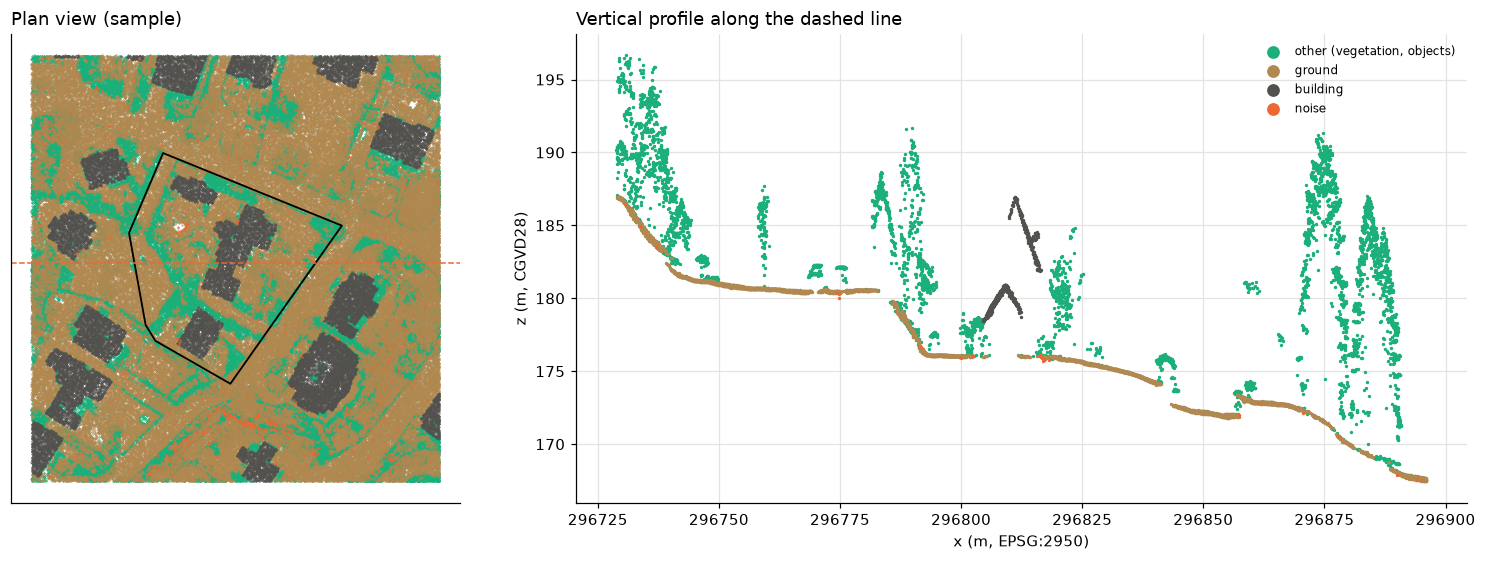

In [18]:
COLORS = {1: "#1baf7a", 2: "#b08850", 6: "#52514e", 7: "#eb6834", 17: "#4a3aa7"}
ymid = per.geometry.iloc[0].centroid.y
strip = pts[(pts.y - ymid).abs() < 1.0]                 # a 2 m wide vertical slice
sub = pts.sample(min(len(pts), 250_000), random_state=0)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.7]})
for c, g in sub.groupby("cls"):
    a1.scatter(g.x, g.y, s=0.15, color=COLORS.get(c, "k"), rasterized=True)
per.boundary.plot(ax=a1, color="k", lw=1.2)
a1.axhline(ymid, color="#eb6834", lw=1, ls="--")
a1.set_title("Plan view (sample)", loc="left")
a1.set_aspect("equal"); a1.set_xticks([]); a1.set_yticks([])
for c, g in strip.groupby("cls"):
    a2.scatter(g.x, g.z, s=1.5, color=COLORS.get(c, "k"), label=CLASSES.get(c, c))
a2.set_title("Vertical profile along the dashed line", loc="left")
a2.set_xlabel("x (m, EPSG:2950)"); a2.set_ylabel("z (m, CGVD28)")
a2.legend(markerscale=6, frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

The profile shows the three kinds of surfaces the visibility model must distinguish: the **ground**, the
**buildings** (opaque) and the class 1 points above the ground, mostly **tree crowns** (semi-transparent:
the laser goes through the leafless branches, and so does a line of sight).

A useful indicator of vegetation inside class 1 is the share of points coming from **multiple-return
pulses**: foliage produces several echoes, a roof edge or a pole usually one.

In [19]:
other = pts[pts.cls == 1]
print(f"class 1 points from multiple-return pulses: {100 * (other.nret > 1).mean():.0f} %")
print(f"first returns that reach the ground (whole area): {100 * (pts[pts.ret == 1].cls == 2).mean():.0f} %")

class 1 points from multiple-return pulses: 69 %
first returns that reach the ground (whole area): 41 %


## 4. From points to rasters

`src.rasters` never loads a tile in memory: it reads chunks of 5 million points, assigns each point to its
pixel and accumulates **mergeable statistics** per class (count, sum, min, max). Merging two chunks gives
exactly the statistics of their union, so memory stays constant and the result does not depend on the
chunking. For a pixel $p$ with ground points $G_p$, class 1 points $O_p$ and first returns $F_p$:

$$
\text{DTM}(p) = \frac{1}{|G_p|} \sum_{q \in G_p} z_q, \qquad
\text{DSM}(p) = \max_{q \in p,\ q \notin \text{noise}} z_q, \qquad
h_\text{veg}(p) = \max_{q \in O_p} z_q - \text{DTM}(p).
$$

Pixels without any ground point (under buildings) are filled by inverse-distance interpolation and flagged
in `dtm_filled.tif`. A toy example with 5 points on a 3 × 2 grid, read in two chunks:

In [20]:
from src.rasters import Accumulator, pixel_index
from src.site import Grid

toy = Grid(crs="EPSG:2950", xmin=0, ymin=0, xmax=3, ymax=2, res=1.0)   # 3 columns x 2 rows
x = np.array([0.2, 0.7, 1.5, 2.9, 2.1])
y = np.array([1.5, 1.2, 0.5, 0.1, 1.9])
z = np.array([10.0, 12.0, 11.0, 15.0, 9.0])
idx, inside = pixel_index(x, y, toy)                 # row 0 at the top (ymax)
acc = Accumulator(toy.width * toy.height)
acc.add(idx[:2], z[:2])                              # chunk 1
acc.add(idx[2:], z[2:])                              # chunk 2
print("pixel index:", idx)
print("count\n", acc.count.reshape(2, 3))
print("mean\n", acc.mean().reshape(2, 3))
print("max\n", acc.max().reshape(2, 3))

pixel index: [0 0 4 5 2]
count
 [[2 0 1]
 [0 1 1]]
mean
 [[11. nan  9.]
 [nan 11. 15.]]
max
 [[12. nan  9.]
 [nan 11. 15.]]


### Vegetation as a semi-transparent medium

Beer-Lambert's law links the vertical **gap fraction** of a canopy of height $h_\text{veg}$ to an extinction
coefficient $k$ [m⁻¹]: $P_\text{gap} = e^{-k h_\text{veg}}$. The LiDAR measures $P_\text{gap}$ directly:
it is the share of **first returns** that reach the ground (a second return on the ground only exists
because the pulse already hit something). With a Laplace correction, so that a pixel without any ground
return does not give $k = \infty$:

$$
\hat P_\text{gap}(p) = \frac{n^{(1)}_\text{ground}(p) + 0.5}{n^{(1)}(p) + 1},
\qquad
k(p) = \frac{-\ln \hat P_\text{gap}(p)}{h_\text{veg}(p)} .
$$

A line of sight crossing a length $\ell$ of vegetation is then attenuated by $e^{-k \ell}$: this is what
turns a visible / invisible map into a **probability**.

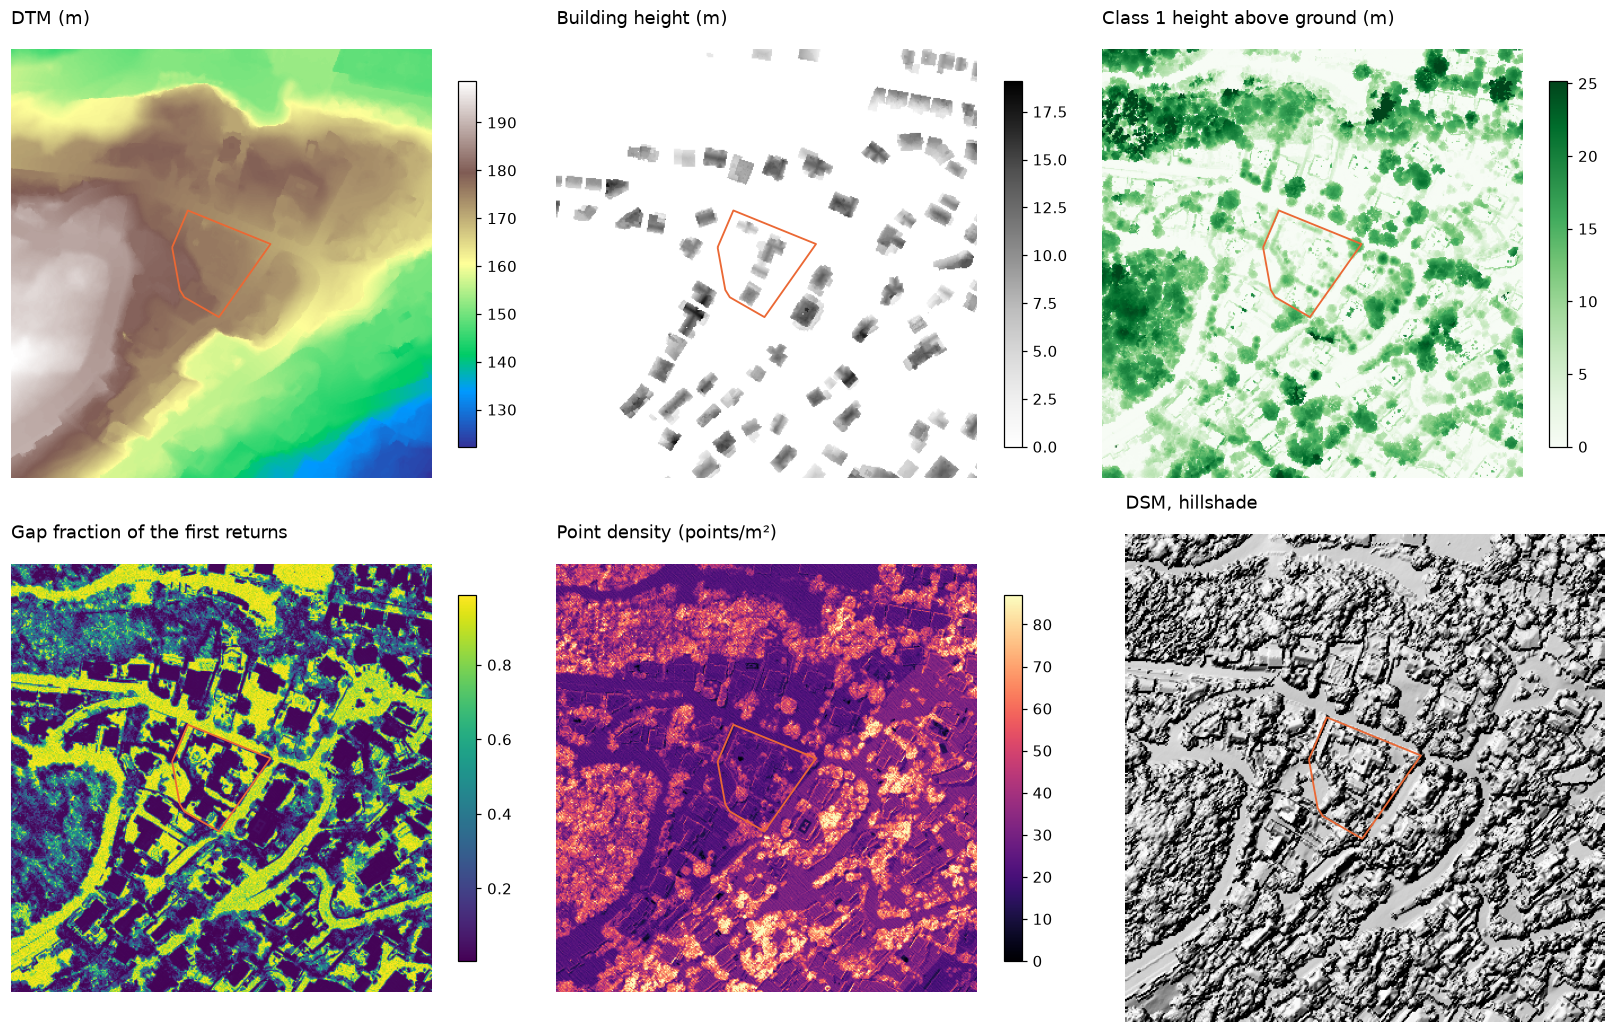

interpolated DTM pixels: 16.7 % (mostly under buildings)


In [21]:
from src.analysis import hillshade
from src.viewshed import read

rd = Path(cfg["rasters"]["out_dir"])
R = {n: read(rd / f"{n}.tif") for n in ("dtm", "dsm", "building_h", "other_h", "gap_fraction",
                                        "density")}
ext = (grid.xmin, grid.xmax, grid.ymin, grid.ymax)
panels = [("dtm", "DTM (m)", "terrain"), ("building_h", "Building height (m)", "Greys"),
          ("other_h", "Class 1 height above ground (m)", "Greens"),
          ("gap_fraction", "Gap fraction of the first returns", "viridis"),
          ("density", "Point density (points/m²)", "magma"), ("dsm", "DSM, hillshade", None)]
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for ax, (n, title, cmap) in zip(axes.ravel(), panels):
    if cmap is None:
        im = ax.imshow(hillshade(np.nan_to_num(R[n], nan=np.nanmedian(R[n]))), extent=ext,
                       cmap="Greys_r")
    else:
        vmax = np.nanpercentile(R[n], 99) if n in ("other_h", "density") else None
        im = ax.imshow(R[n], extent=ext, cmap=cmap, vmax=vmax)
        fig.colorbar(im, ax=ax, shrink=0.75)
    per.boundary.plot(ax=ax, color="#eb6834", lw=1.2)
    ax.set_title(title, loc="left"); ax.set_axis_off()
plt.tight_layout(); plt.show()
filled = read(rd / "dtm_filled.tif")
print(f"interpolated DTM pixels: {100 * np.nanmean(filled):.1f} % (mostly under buildings)")

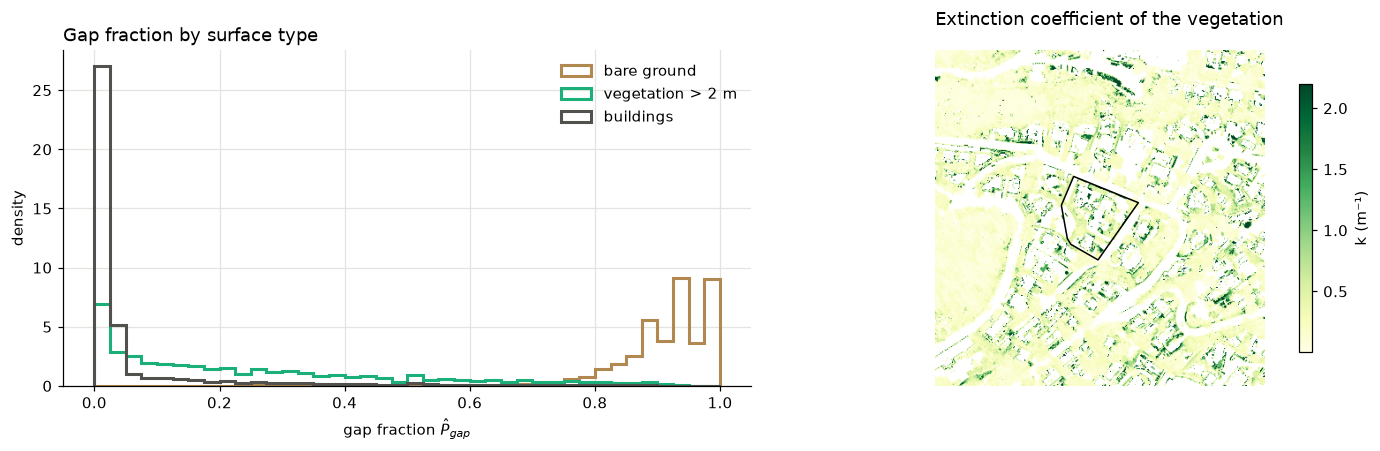

,P_gap,k_per_m,transmittance_10m
0,0.72,0.030,0.742
1,0.25,0.126,0.284
2,0.02,0.356,0.029


In [22]:
from src.viewshed import prepare_surfaces

s = prepare_surfaces(cfg)                     # z_opaque, z_veg, k_ext, z_tgt on the grid
building = R["building_h"] > 0
veg = (R["other_h"] > 2) & ~building
bare = (R["other_h"] < 0.3) & ~building
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.linspace(0, 1, 41)
for m, lab, col in ((bare, "bare ground", "#b08850"), (veg, "vegetation > 2 m", "#1baf7a"),
                    (building, "buildings", "#52514e")):
    a1.hist(R["gap_fraction"][m], bins=bins, histtype="step", lw=2, density=True, color=col, label=lab)
a1.set_xlabel("gap fraction $\\hat P_{gap}$"); a1.set_ylabel("density"); a1.legend(frameon=False)
a1.set_title("Gap fraction by surface type", loc="left")
im = a2.imshow(np.where(s.k_ext > 0, s.k_ext, np.nan), extent=ext, cmap="YlGn",
               vmax=np.nanpercentile(s.k_ext[s.k_ext > 0], 98))
per.boundary.plot(ax=a2, color="k", lw=1)
fig.colorbar(im, ax=a2, shrink=0.8, label="k (m⁻¹)")
a2.set_title("Extinction coefficient of the vegetation", loc="left"); a2.set_axis_off()
plt.tight_layout(); plt.show()

rows = []
for p in (0.72, 0.25, 0.02):
    k = -np.log(p) / 11.0                      # an 11 m tree
    rows.append(dict(P_gap=p, k_per_m=round(k, 3), transmittance_10m=round(np.exp(-10 * k), 3)))
pd.DataFrame(rows)

A leafless maple lets most of the light through ($P_\text{gap} \approx 0.7$), a conifer almost none. The
same estimator handles solid objects without any extra rule: a car has no first return on the ground, so
its $k$ is large and a ray crossing it is blocked in practice.

## 5. Candidate sensor positions

The sensors can only go where they could be installed:

| Support | Rule | Heights | Cost |
|---|---|---|---|
| Fence mast | every 20 m along the fence, 1 m inside | 4, 6, 8, 10 m | 1.0 + 0.10 / m |
| Interior mast | 25 m grid, at least 2 m from buildings | 4, 6, 8, 10 m | 1.0 + 0.10 / m |
| Roof corner | corners of the simplified footprint, 1.5 m from the edge, checked against the LiDAR roof | 2, 4 m | 0.8 + 0.10 / m |

The elevation of a support is read on the DTM (masts) or on the DSM (roofs).

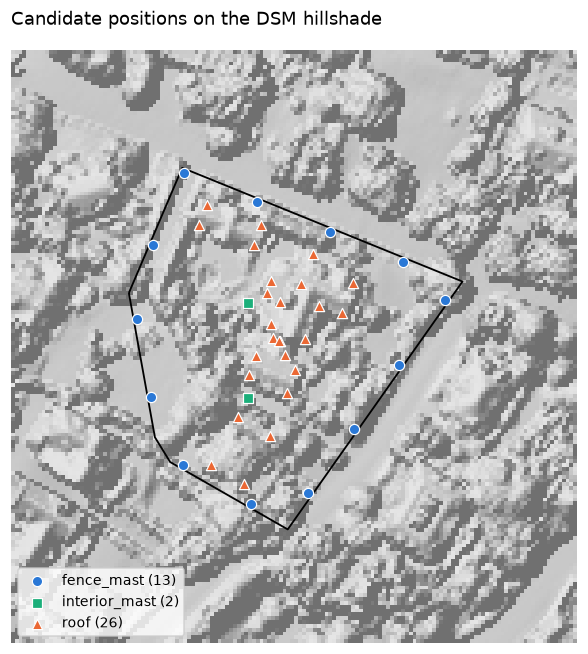

41 positions, 112 (position, height) pairs


,n,mean_support_z,mean_vegetation_h
support,,,
fence_mast,13,175.9,3.8
interior_mast,2,176.0,3.6
roof,26,182.1,NaN


In [23]:
cand = gpd.read_file(cfg["candidates"]["output"])
hs = hillshade(np.nan_to_num(R["dsm"], nan=np.nanmedian(R["dsm"])))
r0 = int((grid.ymax - (per.total_bounds[3] + 30)) / grid.res)
r1 = int((grid.ymax - (per.total_bounds[1] - 30)) / grid.res)
c0 = int((per.total_bounds[0] - 30 - grid.xmin) / grid.res)
c1 = int((per.total_bounds[2] + 30 - grid.xmin) / grid.res)
sub_ext = (grid.xmin + c0, grid.xmin + c1, grid.ymax - r1, grid.ymax - r0)

fig, ax = plt.subplots(figsize=(7.5, 7))
ax.imshow(hs[r0:r1, c0:c1], extent=sub_ext, cmap="Greys_r", vmin=-0.8, vmax=1.4)
per.boundary.plot(ax=ax, color="k", lw=1.2)
style = {"fence_mast": ("o", "#2a78d6"), "interior_mast": ("s", "#1baf7a"), "roof": ("^", "#eb6834")}
for sup, g in cand.groupby("support"):
    mk, col = style[sup]
    ax.scatter(g.geometry.x, g.geometry.y, marker=mk, s=45, color=col, edgecolor="white", lw=0.8,
               label=f"{sup} ({len(g)})", zorder=5)
ax.legend(frameon=True, fontsize=9, loc="lower left")
ax.set_title("Candidate positions on the DSM hillshade", loc="left"); ax.set_axis_off()
plt.show()

n_pairs = sum(len(h.split(",")) for h in cand["heights_m"])
print(f"{len(cand)} positions, {n_pairs} (position, height) pairs")
cand.groupby("support").agg(n=("id", "size"), mean_support_z=("z_support", "mean"),
                            mean_vegetation_h=("h_vegetation", "mean")).round(1)

Some masts stand in vegetation taller than 3 m: they are kept, and the next notebooks show what they can
and cannot see.

**Next:** [02. The visibility engine](02_visibility_engine.ipynb) computes, for each (position, height)
pair, the optical depth of the line of sight towards every cell.